# LATIHAN CLUSTERING MENGGUNAKAN DBSCAN

# A.MEMBUAT FUNGSI DBSCAN sendiri

In [25]:
import numpy as np

def dbscan(dataset, eps, MinPts):
    # Cluster index
    C = 0
    
    # Convert dataset to a list of tuples for hashability
    dataset = [tuple(point) for point in dataset]
    
    # Set up lists to keep track of visited points and cluster assignments
    visited = set()
    clusters = {}
    
    def distance(p1, p2):
        # Define a distance function; assuming Euclidean distance
        return np.sqrt(np.sum((np.array(p1) - np.array(p2)) ** 2))
    
    def find_neighbors(p):
        return [q for q in dataset if distance(p, q) <= eps]
    
    # Iterate over each point in the dataset
    for p in dataset:
        if p in visited:
            continue
        
        visited.add(p)
        
        # Find neighbors of point p
        neighbors = find_neighbors(p)
        
        if len(neighbors) < MinPts:
            # Mark p as noise if it doesn't have enough neighbors
            clusters[p] = 'Noise'
        else:
            # Increment cluster index
            C += 1
            
            # Start a new cluster
            clusters[p] = C
            
            # Expand the cluster
            i = 0
            while i < len(neighbors):
                p_prime = neighbors[i]
                if p_prime not in visited:
                    visited.add(p_prime)
                    neighbors_prime = find_neighbors(p_prime)
                    
                    if len(neighbors_prime) >= MinPts:
                        neighbors.extend(neighbors_prime)
                
                if p_prime not in clusters:
                    clusters[p_prime] = C
                
                i += 1
    
    return clusters


# Menggunakan fungsi dbscan yang dibuat untuk klastering

In [30]:
# Contoh dataset (misalnya, data 2D)
dataset = np.array([
    [1, 2],
    [2, 2],
    [2, 3],
    [8, 7],
    [8, 8],
    [25, 80],
    [20,40],
    [10,9]
])

# Definisikan parameter
eps = 2.0       # Jarak maksimum untuk menganggap titik sebagai tetangga
MinPts = 2      # Jumlah minimum titik yang diperlukan untuk membentuk klaster

# Jalankan algoritma DBSCAN
clusters = dbscan(dataset, eps, MinPts)

## visualisasikan

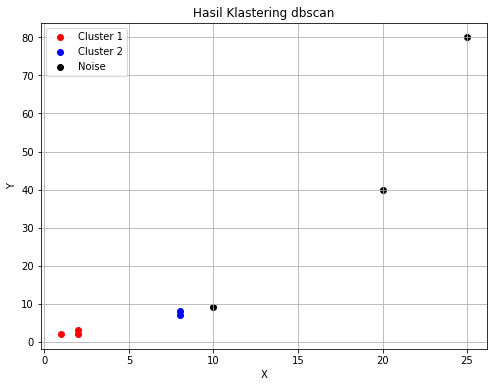

In [39]:
# Convert the dataset to numpy array for plotting
dataset = np.array(dataset)

# Plotting
plt.figure(figsize=(8, 6))

# Define colors for clusters and noise
color_map = {1: 'red', 2: 'blue'}
noise_color = 'black'

# Plot clusters
for point, cluster_id in clusters.items():
    if cluster_id == 'Noise':
        plt.scatter(point[0], point[1], color=noise_color, marker='o', label='Noise')
    else:
        # Use default color if cluster_id is not in color_map
        color = color_map.get(cluster_id, 'gray')
        plt.scatter(point[0], point[1], color=color, marker='o', label=f'Cluster {cluster_id}')

# Remove duplicate labels
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Hasil Klastering dbscan')
plt.grid(True)
plt.show()

# B. Klastering dengan Memanfaatkan Library Python

# Langkah 1: siapkan library yang diperlukan.
Pada contoh ini, perlu library:
1. numpy  diperlukan untuk manipulasi data numerik.
2. matplotlib , diperlukan untuk visualisasi data
3. make_blobs untuk membuat data dummy
4. model DBSCAN dari sklearn


In [75]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_blobs 
from sklearn.cluster import DBSCAN

## Langkah 2: siapkan data
Pada contoh ini menggunakan data dummy yang dibangkitkan dengan  make_blobs.
make_blobs adalah fungsi dari pustaka scikit-learn yang digunakan untuk membuat dataset sintetis berbentuk klaster. Fungsi ini sangat berguna untuk pengujian algoritma clustering atau pengelompokan, seperti k-means, DBSCAN, hierarchical clustering, dan lainnya. 
Dengan make_blobs, Anda dapat membuat data sampel dengan jumlah klaster, pusat klaster, dan distribusi tertentu.



In [15]:
X, _ = make_blobs(n_samples=300, centers=[[1, 1], [-1, -1], [1, -1]], cluster_std=0.4, random_state=0)

Penjelasan Sintak diatas:<br>
X, _ :

Make_blobs mengembalikan dua objek: data sampel X dan label klaster y.
X adalah array NumPy yang berisi koordinat titik-titik data yang dihasilkan.
Tanda garis bawah (_) digunakan untuk mengabaikan variabel kedua (y) yang dikembalikan oleh fungsi karena dalam kasus ini, kita hanya tertarik pada titik-titik data (X) dan tidak memerlukan label klaster.
make_blobs:

Fungsi ini digunakan untuk membuat dataset sintetis yang berbentuk klaster.
n_samples=300:

Menentukan jumlah total titik data yang ingin dibuat dalam dataset. Dalam hal ini, dataset akan memiliki 300 sampel.
centers=[[1, 1], [-1, -1], [1, -1]]:

Menentukan pusat (centroid) dari klaster yang akan dibuat.
Dalam hal ini, ada tiga klaster, masing-masing dengan pusat pada koordinat (1, 1), (-1, -1), dan (1, -1).
cluster_std=0.4:

Menentukan deviasi standar dari klaster, yang mengontrol sebaran data di sekitar pusat klaster.
Semakin kecil nilai cluster_std, semakin rapat data di sekitar pusat klaster; nilai 0.4 menunjukkan bahwa titik data akan tersebar di sekitar pusat dengan sedikit variabilitas.
random_state=0:

Menentukan nilai untuk pengaturan acak. random_state digunakan untuk membuat hasil yang dapat direproduksi; artinya, setiap kali kode ini dijalankan, dataset yang dihasilkan akan sama.
random_state=0 adalah nilai acak tertentu yang memastikan dataset yang sama dihasilkan setiap kali kode dieksekusi.

In [12]:
#tampilkan data
X

array([[ 1.38003537,  0.93945712],
       [-0.21763508, -0.84396267],
       [-1.1413727 , -1.64658968],
       [ 0.817787  ,  1.00699166],
       [ 1.18626498,  0.38550253],
       [-0.93739738, -0.90712759],
       [ 1.52765475, -1.35296753],
       [ 0.46711534, -1.78744988],
       [-1.21714459, -0.83357998],
       [ 1.2689179 ,  1.16298473],
       [ 1.37698725, -1.1070379 ],
       [ 0.95871246,  1.1642394 ],
       [ 0.72217286,  0.94014618],
       [ 0.10415838, -0.83940038],
       [ 1.20931066,  0.93138147],
       [ 0.90319207, -0.39269553],
       [ 0.79299238, -1.39153194],
       [ 0.77227518, -0.89203826],
       [ 0.84190841, -1.46376821],
       [ 0.61155817, -0.87407312],
       [ 1.30441509,  1.04867001],
       [ 0.54101254,  0.82487198],
       [ 0.79613913,  0.82477028],
       [ 0.82593858,  1.73970549],
       [ 0.81326178, -1.56676245],
       [ 0.86083514,  1.06253959],
       [ 1.14833   , -0.94317528],
       [-1.12360519, -1.67040152],
       [ 1.32022592,

### Langkah 3: Lakukan klastering dg model DBSCAN


In [16]:
#Parameter eps dan min_samples digunakan untuk menentukan bagaimana klaster akan terbentuk.
# eps adalah jarak untuk menentukan tetangga, min_samples adalah jumlah anggota minimal tiap klaster
dbscan = DBSCAN (eps=0.3, min_samples=5)
clusters = dbscan.fit_predict(X)

### Langkah 4: Visualisasi hasil clustering


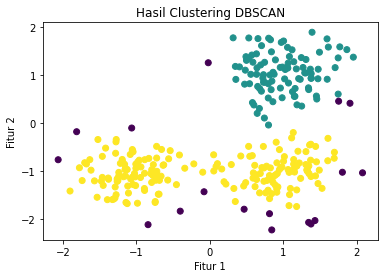

In [17]:
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', marker='o')
plt.title("Hasil Clustering DBSCAN")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

# C. Penerapan Analisis Klaster Menggunakan DBSCA untuk data IRIS 

# Langkah 1: siapkan library

In [41]:
# install library : pandas dan numpy
import pandas as pd
import numpy as np

# Langkah 2: load data

In [48]:
#tempat data disimpan di folder. #Anda harus menyesuaikan dengan path dimana Anda menyimpan dataset yang akan digunakan.
data = pd.read_csv("dataset/Iris.csv") 


In [47]:
#coba menampilkan hasil load dataset
data

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


# Langkah 3: Preprocessing ( konversi data, normalisasi data)

In [88]:
#cari kelas nya, brt cari nilai uniq di kelas / species

kelas=data.groupby(['Species']).sum()
print(kelas)

                   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
Species                                                             
Iris-setosa      1275          250.3         170.9           73.2   
Iris-versicolor  3775          296.8         138.5          213.0   
Iris-virginica   6275          329.4         148.7          277.6   

                 PetalWidthCm  
Species                        
Iris-setosa              12.2  
Iris-versicolor          66.3  
Iris-virginica          101.3  


In [89]:
#atau cara lain untuk cek jumlah kelas, pakai count
item_kelas = data["Species"].value_counts()
item_kelas

Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: Species, dtype: int64

# Konversi kelas string menjadi numerik

In [51]:
#ubah varaibel kelas , species menjadi angka. Misal Iris-Setosa=1, Iris-Virginica=2, Iris-versicolor
data.Species.replace(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], [1, 2,3], inplace=True)

In [52]:
#Tampilkan data hasil pengubahan variabel kelas
data

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,1
1,2,4.9,3.0,1.4,0.2,1
2,3,4.7,3.2,1.3,0.2,1
3,4,4.6,3.1,1.5,0.2,1
4,5,5.0,3.6,1.4,0.2,1
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,3
146,147,6.3,2.5,5.0,1.9,3
147,148,6.5,3.0,5.2,2.0,3
148,149,6.2,3.4,5.4,2.3,3


# Normalisasi data

In [78]:
import numpy as np

In [82]:
#normalisasi data jika diperlukan
#standarisasi nilai dengan standar scaling
from sklearn.preprocessing import StandardScaler
#Normalize
var_x = data.drop(["Species"], axis = 1)
var_xx = var_x
# di skalakan/ scaling
var_xxx = StandardScaler().fit_transform(var_xx)
#jika tdk di skalakan maka harus diubah ke array dulu, pakai to_numpy
var_xxxx = var_xx.to_numpy()

In [81]:
# tampilkan hasil normalisasi
var_xxx

array([[1.00e+00, 5.10e+00, 3.50e+00, 1.40e+00, 2.00e-01],
       [2.00e+00, 4.90e+00, 3.00e+00, 1.40e+00, 2.00e-01],
       [3.00e+00, 4.70e+00, 3.20e+00, 1.30e+00, 2.00e-01],
       [4.00e+00, 4.60e+00, 3.10e+00, 1.50e+00, 2.00e-01],
       [5.00e+00, 5.00e+00, 3.60e+00, 1.40e+00, 2.00e-01],
       [6.00e+00, 5.40e+00, 3.90e+00, 1.70e+00, 4.00e-01],
       [7.00e+00, 4.60e+00, 3.40e+00, 1.40e+00, 3.00e-01],
       [8.00e+00, 5.00e+00, 3.40e+00, 1.50e+00, 2.00e-01],
       [9.00e+00, 4.40e+00, 2.90e+00, 1.40e+00, 2.00e-01],
       [1.00e+01, 4.90e+00, 3.10e+00, 1.50e+00, 1.00e-01],
       [1.10e+01, 5.40e+00, 3.70e+00, 1.50e+00, 2.00e-01],
       [1.20e+01, 4.80e+00, 3.40e+00, 1.60e+00, 2.00e-01],
       [1.30e+01, 4.80e+00, 3.00e+00, 1.40e+00, 1.00e-01],
       [1.40e+01, 4.30e+00, 3.00e+00, 1.10e+00, 1.00e-01],
       [1.50e+01, 5.80e+00, 4.00e+00, 1.20e+00, 2.00e-01],
       [1.60e+01, 5.70e+00, 4.40e+00, 1.50e+00, 4.00e-01],
       [1.70e+01, 5.40e+00, 3.90e+00, 1.30e+00, 4.00e-01

Text(0.5, 1.0, ' Plot Data')

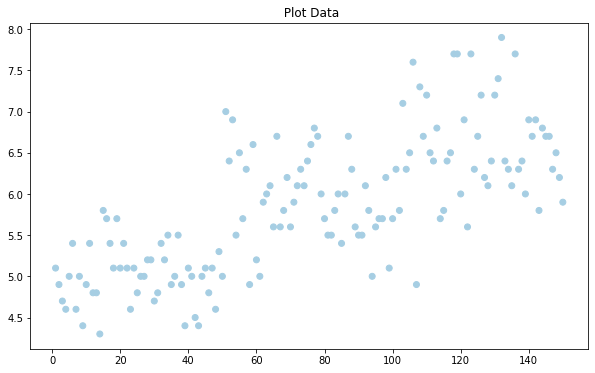

In [89]:
#plot dulu menjadi grafik scatter
#visualisasikan grafik scatter dengan data yg blm diskalakan
y_pred = model_dbs.fit_predict(var_xxxx)
plt.figure(figsize=(10,6))
plt.scatter(var_xxxx[:,0], var_xxxx[:,1],c=y_pred, cmap='Paired')
plt.title(" Plot Data")

# Langkah 4: CLUSTERING dg DBSCAN

In [90]:
from sklearn.cluster import DBSCAN

In [91]:
#buat model DBSCAN dg data yang sdh di scaling/ di skalakan
# paramaeter yang digunakan adalah eps dan minPts-->minimum samples
model_dbs = DBSCAN(eps=0.9, min_samples=20)
model_dbs.fit(var_xxx)

DBSCAN(eps=0.9, min_samples=20)

In [92]:
#deteksi outlier
model_dbs.labels_[model_dbs.labels_ == -1].size

72

Text(0.5, 1.0, 'Clusters Iris dengan DBSCAN')

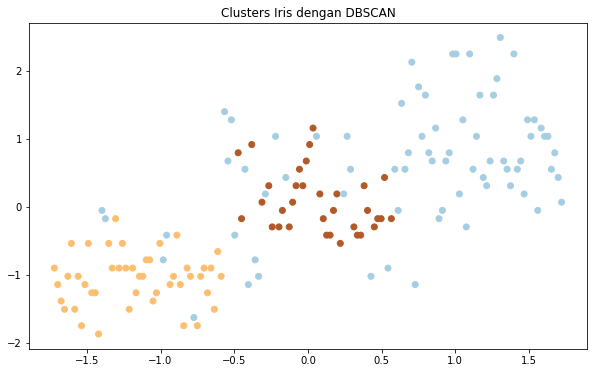

In [88]:
#Visualisasikan
y_pred = model_dbs.fit_predict(var_xxx)
plt.figure(figsize=(10,6))
plt.scatter(var_xxx[:,0], var_xxx[:,1],c=y_pred, cmap='Paired')
plt.title("Clusters Iris dengan DBSCAN")

# Analisis hasil klaster menggunakan silhoute score

In [93]:
from sklearn.metrics import silhouette_score

# Hitung Silhouette Score hanya untuk data yang tidak dianggap noise
labels = model_dbs.labels_
mask = labels != -1  # Hanya ambil titik yang bukan noise
score = silhouette_score(var_xxxx[mask], labels[mask])
print(f"Silhouette Score: {score:.2f}")

Silhouette Score: 0.66


Dengan hasil silhoute score 0.66 artinya melampui nilai treshold minimal 5 ( nilai treshold menurut jurnal- jurnal penelitian adalah 5). Skor semakin tinggi semakin baik.